# 03 · Using the explanations

We simplify the model and examine business levers. Fitting, redundancy checks and the numerical selection rule use
training data only. Because notebook 02 already inspected test explanations, this extension is **exploratory**.
The test comparison describes this sample; a fresh cohort is needed for independent confirmation.

In [1]:
import json
import contextlib
import io
import sys
import warnings
from pathlib import Path

import dice_ml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from raiutils.exceptions import UserConfigValidationException
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable when the notebook runs from notebooks/
from src.data import download, load_clean
from src.modeling import (SEED, build_pipeline, churn_metrics, cv_and_gap, cv_fold_scores, expected_cost,
                          make_models, split)
from src.xai import (MAX_RANDOMIZED_SPEARMAN, RANDOM_QUANTILE, ShiftedThreshold, bootstrap_rows, fewest_changes,
                     importance_under_refits, median_case, reference_auc_drops, shap_by_feature, shuffle_labels, top_k_vs_random_k)
from src.plots import FIGURES, deletion_plot, save, use_style

use_style()

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

X, y = load_clean(download())
X_train, X_test, y_train, y_test = split(X, y)
COST_RATIO = 5                                   # the assumption of notebook 01 (a missed churner = 5 wasted offers)
THRESHOLD = 1 / (1 + COST_RATIO)                 # 0.167: optimal for calibrated probabilities, chosen in advance, not fitted
# (notebooks 01 and 02 use 0.17, the value picked on out-of-fold predictions; the two are practically the same)

## 1. Improving the model (use 4.1)

**Hypothesis.** The original explanations motivate examining MonthlyCharges and TotalCharges. The reconstruction
checks below use training only: contracted services almost reconstruct MonthlyCharges, and tenure, MonthlyCharges
and their product almost reconstruct TotalCharges. Near-reconstruction does not prove zero conditional information.
We test whether the two variables are practically dispensable for this model under explicit AUC and cost tolerances.
This training evidence does not undo the earlier test inspection; the full extension remains exploratory.

In [2]:
baseline_search = make_models()["xgboost"].fit(X_train, y_train)     # the model of notebooks 01 and 02
baseline = baseline_search.best_estimator_

services = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
folds = KFold(5, shuffle=True, random_state=SEED)
r2_price = cross_val_score(build_pipeline(LinearRegression()), X_train[services], X_train["MonthlyCharges"],
                           cv=folds, scoring="r2").mean()
product = X_train.assign(tenure_x_monthly=X_train["tenure"] * X_train["MonthlyCharges"])[
    ["tenure", "MonthlyCharges", "tenure_x_monthly"]]
r2_total = cross_val_score(LinearRegression(), product, X_train["TotalCharges"], cv=folds, scoring="r2").mean()
print(f"MonthlyCharges from the services alone:                            CV R2 = {r2_price:.3f}")
print(f"TotalCharges from tenure, MonthlyCharges and their product:        CV R2 = {r2_total:.3f}")

candidates = ["MonthlyCharges", "TotalCharges"]
train_importance = pd.Series(permutation_importance(baseline, X_train, y_train, scoring="roc_auc", n_repeats=10,
                                                    random_state=SEED).importances_mean, index=X_train.columns)
print("Permutation importance on the training set (fall in ROC-AUC when shuffled):",
      train_importance[candidates].round(4).to_dict(),
      "| median of the other features:", round(float(train_importance.drop(candidates).median()), 4))

MonthlyCharges from the services alone:                            CV R2 = 0.999
TotalCharges from tenure, MonthlyCharges and their product:        CV R2 = 0.999


Permutation importance on the training set (fall in ROC-AUC when shuffled): {'MonthlyCharges': 0.0082, 'TotalCharges': 0.0061} | median of the other features: 0.0011


**Experiment.** Four versions of the main model, each tuned by the same nested cross-validation, on the same
folds, so that each can be compared with the baseline **fold by fold** (the fold-to-fold spread, about 0.012 of AUC,
is much larger than the differences we look for; paired differences remove most of it).

**Decision rule, fixed before running.** Adopt the version with the fewest features whose average paired difference
with the baseline is no worse than **-0.003 in ROC-AUC** and no worse than **+0.005 in expected cost per customer**
(ties between equally small versions go to the higher AUC). If none qualifies, the baseline stays. Only training data
are used for this choice.

In [3]:
AUC_TOLERANCE, COST_TOLERANCE = 0.003, 0.005     # the decision rule, fixed before running
versions = {
    "baseline (19 features)": [],
    "without MonthlyCharges": ["MonthlyCharges"],
    "without TotalCharges": ["TotalCharges"],
    "without both": ["MonthlyCharges", "TotalCharges"],
}
fold_scores = {name: cv_fold_scores(make_models()["xgboost"], X_train.drop(columns=dropped), y_train,
                                    THRESHOLD, COST_RATIO)
               for name, dropped in versions.items()}
baseline_folds = fold_scores["baseline (19 features)"]
summary = pd.DataFrame({name: {
    "features": X_train.shape[1] - len(versions[name]),
    "CV AUC": s["auc"].mean(), "AUC vs baseline": (s["auc"] - baseline_folds["auc"]).mean(),
    "  (std of paired diff)": (s["auc"] - baseline_folds["auc"]).std(),
    "CV PR-AUC": s["pr_auc"].mean(), "CV Brier": s["brier"].mean(),
    "recall": s["recall"].mean(), "precision": s["precision"].mean(),
    "cost": s["cost"].mean(), "cost vs baseline": (s["cost"] - baseline_folds["cost"]).mean()}
    for name, s in fold_scores.items()}).T
summary.round(4)

,features,CV AUC,AUC vs baseline,(std of paired diff),CV PR-AUC,CV Brier,recall,precision,cost,cost vs baseline
baseline (19 features),19.0,0.8508,0.0000,0.0000,0.6720,0.1330,0.8970,0.4566,0.4205,0.0000
without MonthlyCharges,18.0,0.8507,-0.0001,0.0013,0.6721,0.1330,0.8957,0.4543,0.4242,0.0037
without TotalCharges,18.0,0.8506,-0.0002,0.0004,0.6709,0.1334,0.8950,0.4527,0.4269,0.0064
without both,17.0,0.8509,0.0001,0.0013,0.6719,0.1330,0.8963,0.4559,0.4215,0.0011


In [4]:
acceptable = summary[(summary["AUC vs baseline"] >= -AUC_TOLERANCE) & (summary["cost vs baseline"] <= COST_TOLERANCE)]
chosen = acceptable.sort_values(["features", "AUC vs baseline"], ascending=[True, False]).index[0]
print("Versions that pass the rule:", list(acceptable.index))
print("Adopted:", chosen)

Versions that pass the rule: ['baseline (19 features)', 'without MonthlyCharges', 'without both']
Adopted: without both


**Before and after.** The variant is selected by the training CV rule above. We then describe the baseline and
adopted model on the already inspected test sample, without using test scores to switch variants. This is not an
untouched confirmatory comparison. Both versions use the same analytic threshold 1/(1+5), fixed independently of
these folds; notebooks 01 and 02 use 0.17 selected on out-of-fold predictions.

In [5]:
searches = {"before": baseline_search,
            "after": make_models()["xgboost"].fit(X_train.drop(columns=versions[chosen]), y_train)}
dropped_in = {"before": [], "after": versions[chosen]}
fitted, comparison = {}, {}
for label, search in searches.items():
    X_a, X_b = X_train.drop(columns=dropped_in[label]), X_test.drop(columns=dropped_in[label])
    scores = cv_and_gap(make_models()["xgboost"], X_a, y_train, X_b, y_test)      # nested CV on train; test scored once
    proba_b = search.predict_proba(X_b)[:, 1]
    at_threshold = churn_metrics(y_test, proba_b, THRESHOLD)
    fitted[label] = (search.best_estimator_, X_a, X_b)
    comparison[label] = {"features": X_a.shape[1], "CV AUC": scores["cv_auc"], "test AUC": scores["test_auc"],
                         "train-CV gap": scores["gap"], "test PR-AUC": scores["test_pr_auc"],
                         "Brier": at_threshold["brier"], "recall": at_threshold["recall"],
                         "precision": at_threshold["precision"],
                         "cost per customer": expected_cost(y_test, proba_b >= THRESHOLD, COST_RATIO)}
pd.DataFrame(comparison).T.round(4)

,features,CV AUC,test AUC,train-CV gap,test PR-AUC,Brier,recall,precision,cost per customer
before,19.0,0.8508,0.8481,0.0082,0.6699,0.1343,0.8850,0.4559,0.4329
after,17.0,0.8509,0.8482,0.0053,0.6691,0.1346,0.8797,0.4576,0.4365


**Do the explanations change?** We refit each version on 8 bootstrap resamples of the training rows and explain the
test set each time. *Stability* is the mean rank correlation (Spearman) between the importance rankings of two refits
(1 = identical), computed on the features both versions share so that the two numbers are comparable. To see where
the credit goes we show the mean absolute SHAP value in log-odds, **not** renormalised: shares of a total would rise
for every remaining feature just because two others were removed.

In [6]:
def stability(refits):
    correlation = refits.T.corr(method="spearman").to_numpy()
    return correlation[np.triu_indices_from(correlation, k=1)].mean()

refits = {label: importance_under_refits(lambda best=best: clone(best), X_a, y_train, X_b, bootstrap_rows, n_refits=8)
          for label, (best, X_a, X_b) in fitted.items()}
shared = list(refits["after"].columns)
display(pd.Series({label: stability(table[shared]) for label, table in refits.items()},
                  name="stability on the shared features (mean Spearman between refits)").round(3))
absolute = pd.DataFrame({label: table.mean() for label, table in refits.items()})     # mean |SHAP|, log-odds
absolute.loc[absolute.max(axis=1).nlargest(7).index].round(3)

before    0.882
after     0.894
Name: stability on the shared features (mean Spearman between refits), dtype: float64

,before,after
tenure,0.556,0.693
Contract,0.612,0.612
InternetService,0.360,0.471
MonthlyCharges,0.252,NaN
OnlineSecurity,0.209,0.196
MultipleLines,0.140,0.182
PaymentMethod,0.173,0.179


### Reading section 1

- **The results meet the practical performance tolerances.** The model does use the two candidates (shuffling them costs 0.008 and 0.006 of
  AUC on the training set, against a median of 0.001 for the other features), but it can get the same information elsewhere,
  and the removal experiment shows it. Removing MonthlyCharges and TotalCharges meets the practical mean-CV tolerances: the paired
  difference of ROC-AUC is +0.0001, with a standard deviation of 0.0013 across folds, about ten times smaller than the raw
  fold spread; PR-AUC and Brier do not move and the cost changes by +0.0011 per customer. The rule fixed in advance adopts
  the version without both (17 features); without TotalCharges alone the cost rule fails (+0.0064).
- **Descriptive comparison on the already inspected test set:** ROC-AUC 0.8481 -> 0.8482, PR-AUC 0.670 -> 0.669, and cost per customer
  0.4329 -> 0.4365 (+0.0035: small, of the size the paired CV allowed, and one test sample of 1,409 customers does not
  support reading more into it). The train-CV gap goes from 0.0082 to 0.0053 (one run, without an interval); both are far below the limit of 0.03.
- **An improvement in stability is not established.** On the 17 features both versions share, the mean rank
  correlation between refits goes from 0.882 to 0.894. It is a small rise that 8 refits cannot separate from noise (we did
  not compute an interval), so we do not claim the explanations became more stable.
- **Where the credit goes** (mean absolute SHAP in log-odds, not renormalised). The 0.25 held by MonthlyCharges is taken over
  mainly by tenure (0.56 -> 0.69, which also inherits what TotalCharges carried) and InternetService (0.36 -> 0.47), with
  MultipleLines rising from 0.14 to 0.18; Contract does not change (0.61). This is an inference from the numbers, not a test:
  the price was the sum of the services, and their credit returns to them.
- **What this is and is not.** A simplification suggested by the explanations and confirmed by cross-validation: similar observed
  performance, fewer features, smaller gap, and no credit given to a price that the services already carry. It is not
  an accuracy gain, which we did not expect since redundant features add no information. The sanity checks of notebook 02
  are repeated on the adopted version in the next section. Meeting the mean-CV tolerances is not a formal non-inferiority test.

## 1.1 Checking the explanations of the adopted model

Validation is repeated after simplification, before interpreting its business levers. The model has already been
selected by training CV; these checks do not choose a new variant. Keep the original diagnostic thresholds (mean
shuffled-label Spearman < 0.5; top-k drop > reference 95th percentile for every k = 1, 2, 3).
Use 10 label-shuffled refits and 10 bootstrap controls. For deletion enumerate all 17 singletons (50 permutations)
and all 136 pairs (10 each), then sample 200 distinct triples (10 each). Reversed SHAP is a negative control.
The protocol extension is reported as post-exploratory evaluation, not a preregistered confirmatory experiment.

,shuffled labels,bootstrap control
mean,0.3537,0.9319
min,-0.0392,0.8456
max,0.5637,0.9779


Final label-randomisation criterion: True


,ranking,k,top_k_drop,random_median,random_low,random_high,reference_subsets,permutations_per_subset,passes
0,xgboost,1,0.0960,0.0013,-0.0000,0.0560,17,50,True
1,reversed,1,0.0000,0.0013,-0.0000,0.0560,17,50,False
2,xgboost,2,0.1863,0.0036,0.0001,0.0954,136,10,True
3,reversed,2,-0.0001,0.0036,0.0001,0.0954,136,10,False
4,xgboost,3,0.2369,0.0069,0.0009,0.1112,200,10,True
5,reversed,3,0.0003,0.0069,0.0009,0.1112,200,10,False


Final deletion criterion: {'reversed': False, 'xgboost': True}


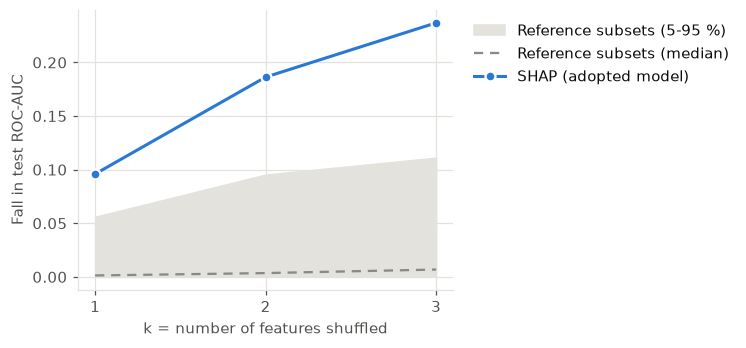

In [7]:
final_model, final_train, final_test = fitted["after"]
final_importance = shap_by_feature(final_model, final_test, final_train)[0].abs().mean()
final_factory = lambda: clone(final_model)
final_shuffled = importance_under_refits(final_factory, final_train, y_train, final_test, shuffle_labels, n_refits=10)
final_control = importance_under_refits(final_factory, final_train, y_train, final_test, bootstrap_rows, n_refits=10)
final_correlations = pd.DataFrame({
    "shuffled labels": final_shuffled.apply(lambda r: r.corr(final_importance, method="spearman"), axis=1),
    "bootstrap control": final_control.apply(lambda r: r.corr(final_importance, method="spearman"), axis=1),
})
display(final_correlations.agg(["mean", "min", "max"]).round(4))
print("Final label-randomisation criterion:", bool(final_correlations["shuffled labels"].mean() < MAX_RANDOMIZED_SPEARMAN))
final_order = list(shap_by_feature(final_model, final_train, final_train)[0].abs().mean().sort_values(ascending=False).index)
final_rows = []
for k in (1, 2, 3):
    repeats = 50 if k == 1 else 10
    reference = reference_auc_drops(final_model, final_test, y_test, final_train.columns, k,
                                    n_random=200, n_repeats=repeats)
    for name, ranking in {"xgboost": final_order, "reversed": final_order[::-1]}.items():
        top, null = top_k_vs_random_k(final_model, final_test, y_test, ranking, k, n_repeats=repeats, reference=reference)
        final_rows.append({"ranking": name, "k": k, "top_k_drop": top, "random_median": np.median(null),
                           "random_low": np.quantile(null, 0.05), "random_high": np.quantile(null, RANDOM_QUANTILE),
                           "reference_subsets": len(reference), "permutations_per_subset": repeats,
                           "passes": bool(top > np.quantile(null, RANDOM_QUANTILE))})
final_deletion = pd.DataFrame(final_rows)
display(final_deletion.round(4))
print("Final deletion criterion:", final_deletion.groupby("ranking")["passes"].all().to_dict())
fig, ax = plt.subplots(figsize=(4.4, 3.3))
deletion_plot(final_deletion, {"xgboost": "SHAP (adopted model)"}, ax)
save(fig, "sanity_deletion_final.png")
plt.show()
final_checks = {
    "label_randomisation": {
        "mean_shuffled_spearman": float(final_correlations["shuffled labels"].mean()),
        "mean_control_spearman": float(final_correlations["bootstrap control"].mean()),
        "passes": bool(final_correlations["shuffled labels"].mean() < MAX_RANDOMIZED_SPEARMAN)},
    "deletion": final_deletion.to_dict("records"),
}

**Interpretation.** The label-shuffle control separates sensitivity to learned signal from refit instability.
The deletion table reports the full diagnostic, including failures if any; reversed SHAP tests whether a bad ranking
can be rejected. A stronger result after feature removal describes alignment with this model's AUC reliance, not
causal validity or a universal improvement in explanation quality. The reference has exhaustive singleton and pair
coverage but retains finite permutation noise; triples remain a seeded sample.

## 2. Business insights and levers (use 4.2)

This section uses the adopted model, fitted on the training set, at the operating threshold of section 1.
**Everything here is about the model's predictions**: it describes associations between customer profiles and churn.
It does not measure the effect of an intervention, which would need an experiment (see the discussion).

### 2.1 Whom to contact first

Ranking customers by predicted risk turns the model into a prioritisation rule when the budget covers only some of
them. The table shows, on the test set, what share of the churners is reached by contacting the top *x %*.

In [8]:
model, X_fit, X_eval = fitted["after"]
dropped = versions[chosen]
proba = model.predict_proba(X_eval)[:, 1]
churned = y_test.to_numpy()

rows = {}
for share in (0.1, 0.2, 0.3, 0.5, 0.7):
    top = np.argsort(-proba)[: int(share * len(proba))]
    rows[f"top {share:.0%}"] = {"churners reached (recall)": churned[top].sum() / churned.sum(),
                                "churn rate in the group": churned[top].mean(),
                                "lift over contacting at random": churned[top].mean() / churned.mean()}
print(f"Model without: {dropped}. At the threshold {THRESHOLD:.2f}, {(proba >= THRESHOLD).mean():.1%} of the customers are flagged.")
pd.DataFrame(rows).T.round(2)

Model without: ['MonthlyCharges', 'TotalCharges']. At the threshold 0.17, 51.0% of the customers are flagged.


,churners reached (recall),churn rate in the group,lift over contacting at random
top 10%,0.29,0.77,2.91
top 20%,0.51,0.68,2.55
top 30%,0.66,0.59,2.21
top 50%,0.87,0.46,1.74
top 70%,0.98,0.37,1.40


### 2.2 Which levers, and how far do they go?

The explanations point to levers the operator controls: the contract, the payment method, paperless billing and the
add-on services (online security and backup, device protection, technical support). Age, gender, partner and
tenure cannot be changed. For each **flagged customer on a month-to-month contract with internet service** we ask the
model: *what is the smallest set of changes to these levers that brings the predicted risk below the threshold?*
There are only a few hundred combinations of the levers, so we try them all and the answer is exact (no search
heuristic); among sets of the same size we keep the one with the lowest risk. The count is of *changes*, not of their
cost: a new contract and a billing setting count the same. Three scenarios: without touching the contract; with a
contract of up to one year; with up to two years.

In [9]:
LEVERS = {"PaymentMethod": sorted(X["PaymentMethod"].unique()), "PaperlessBilling": ["No", "Yes"],
          "OnlineSecurity": ["No", "Yes"], "OnlineBackup": ["No", "Yes"],
          "DeviceProtection": ["No", "Yes"], "TechSupport": ["No", "Yes"]}
CONTRACTS = ["Month-to-month", "One year", "Two year"]
scenarios = {"add-ons and billing only": {**LEVERS}, "+ contract up to one year": {"Contract": CONTRACTS[:2], **LEVERS},
             "+ contract up to two years": {"Contract": CONTRACTS, **LEVERS}}
levers = ["Contract"] + list(LEVERS)

at_risk = ((proba >= THRESHOLD) & (X_eval["Contract"] == "Month-to-month") & (X_eval["InternetService"] != "No")).to_numpy()
pool, before = X_eval[at_risk], proba[at_risk]
print(f"{len(pool)} flagged month-to-month customers with internet service in the test set "
      f"({len(pool) / len(X_eval):.0%} of it); {churned[at_risk].mean():.0%} of them churned")

outcomes = {name: [fewest_changes(model, pool.iloc[[i]], options, THRESHOLD) for i in range(len(pool))]
            for name, options in scenarios.items()}
table, moves = {}, {}
for name, found in outcomes.items():
    solved = [i for i, outcome in enumerate(found) if outcome is not None]
    table[name] = {"below the threshold": len(solved) / len(pool),
                   "one change is enough": sum(len(found[i][0]) == 1 for i in solved) / len(pool),
                   "  of which the contract": sum(set(found[i][0]) == {"Contract"} for i in solved) / len(pool),
                   "median changes": np.median([len(found[i][0]) for i in solved]),
                   "risk before (solved)": before[solved].mean(),
                   "risk after (solved)": np.mean([found[i][1] for i in solved])}
    moves[name] = pd.Series([f"{feature}: {old} -> {new}" for i in solved
                             for feature, (old, new) in found[i][0].items()]).value_counts()
lever_table = pd.DataFrame(table).T
display(lever_table.round(3))
for name, counts in moves.items():
    print(f"{name}: {counts.head(8).to_dict()}")

611 flagged month-to-month customers with internet service in the test set (43% of it); 49% of them churned


,below the threshold,one change is enough,of which the contract,median changes,risk before (solved),risk after (solved)
add-ons and billing only,0.255,0.069,0.000,2.0,0.283,0.148
+ contract up to one year,0.697,0.185,0.185,3.0,0.412,0.140
+ contract up to two years,0.917,0.494,0.494,1.0,0.474,0.121


add-ons and billing only: {'PaperlessBilling: Yes -> No': 118, 'OnlineSecurity: No -> Yes': 105, 'TechSupport: No -> Yes': 61, 'PaymentMethod: Electronic check -> Bank transfer (automatic)': 57, 'OnlineBackup: No -> Yes': 25, 'DeviceProtection: Yes -> No': 6, 'PaymentMethod: Credit card (automatic) -> Bank transfer (automatic)': 1}
+ contract up to one year: {'Contract: Month-to-month -> One year': 426, 'PaperlessBilling: Yes -> No': 257, 'OnlineSecurity: No -> Yes': 224, 'PaymentMethod: Electronic check -> Bank transfer (automatic)': 127, 'TechSupport: No -> Yes': 117, 'OnlineBackup: No -> Yes': 44}
+ contract up to two years: {'Contract: Month-to-month -> Two year': 560, 'PaperlessBilling: Yes -> No': 209, 'OnlineSecurity: No -> Yes': 173, 'PaymentMethod: Electronic check -> Bank transfer (automatic)': 76, 'TechSupport: No -> Yes': 48, 'OnlineBackup: No -> Yes': 14, 'DeviceProtection: Yes -> No': 1}


### 2.3 Counterfactual explanations with DiCE for two customers

DiCE proposes alternative profiles for a customer. Only the specified levers may change; all others stay fixed.
Add-on values are restricted to Yes/No because these customers have internet service. The threshold wrapper maps
our operating boundary to DiCE's 0.5 boundary; reported probabilities are recomputed with the actual model.
Exhaustive search supplies a minimum change count within the allowed discrete combinations. This is not minimum
financial cost or proof of feasibility: customer consent, acceptance, causal effects and real intervention costs
are not modelled. The examples are median-risk customers, with the second restricted to tenure <= 12 months.

In [10]:
in_pool = np.zeros(len(X_eval), dtype=bool); in_pool[np.flatnonzero(at_risk)] = True
picks = {"median-risk flagged customer": median_case(proba, in_pool),
         "median-risk, tenure <= 12": median_case(proba, in_pool & (X_eval["tenure"].to_numpy() <= 12))}

numeric = [c for c in X_fit.columns if X_fit[c].dtype.kind in "if"]
data = dice_ml.Data(dataframe=pd.concat([X_fit, y_train.rename("Churn")], axis=1), continuous_features=numeric,
                    outcome_name="Churn")
generator = dice_ml.Dice(data, dice_ml.Model(model=ShiftedThreshold(model, THRESHOLD), backend="sklearn"), method="random")
ranges = {name: ["No", "Yes"] for name in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]}

def describe(original, changed):
    return "; ".join(f"{f}: {original[f].iloc[0]} -> {changed[f]}" for f in levers if original[f].iloc[0] != changed[f])

rows = []
for who, position in picks.items():
    customer = X_eval.iloc[[position]]
    best = fewest_changes(model, customer, scenarios["+ contract up to two years"], THRESHOLD)
    rows.append({"customer": who, "source": "current", "changes": "-", "n changes": 0, "minimal": "", "P(churn)": proba[position]})
    rows.append({"customer": who, "source": "exhaustive minimum", "n changes": len(best[0]), "minimal": "yes",
                 "changes": "; ".join(f"{f}: {a} -> {b}" for f, (a, b) in best[0].items()), "P(churn)": best[1]})
    np.random.seed(SEED)
    try:
        with warnings.catch_warnings(), contextlib.redirect_stderr(io.StringIO()):   # DiCE prints a progress bar
            warnings.simplefilter("ignore")
            proposals = generator.generate_counterfactuals(customer, total_CFs=3, desired_class="opposite",
                                                           features_to_vary=levers, permitted_range=ranges,
                                                           random_seed=SEED)
        for proposal in proposals.cf_examples_list[0].final_cfs_df.drop(columns="Churn").to_dict("records"):
            proposal = pd.Series(proposal)
            changes = sum(customer[f].iloc[0] != proposal[f] for f in levers)
            rows.append({"customer": who, "source": "DiCE", "changes": describe(customer, proposal), "n changes": changes,
                         "minimal": "yes" if changes == len(best[0]) else "no",
                         "P(churn)": model.predict_proba(pd.DataFrame([proposal])[X_eval.columns].astype(X_eval.dtypes))[0, 1]})
    except UserConfigValidationException:
        rows.append({"customer": who, "source": "DiCE", "changes": "no counterfactual found", "n changes": np.nan,
                     "minimal": "", "P(churn)": np.nan})
dice_results = pd.DataFrame(rows).sort_values(["customer", "source"]).reset_index(drop=True)
dice_results.round(2)

,customer,source,changes,n changes,minimal,P(churn)
0,median-risk flagged customer,DiCE,Contract: Month-to-month -> Two year; PaperlessBilling: Yes -> No,2,yes,0.12
1,median-risk flagged customer,DiCE,Contract: Month-to-month -> Two year; PaymentMethod: Electronic check -> Mailed check,2,yes,0.12
2,median-risk flagged customer,DiCE,Contract: Month-to-month -> Two year; OnlineSecurity: No -> Yes,2,yes,0.12
3,median-risk flagged customer,current,-,0,,0.50
4,median-risk flagged customer,exhaustive minimum,Contract: Month-to-month -> Two year; PaperlessBilling: Yes -> No,2,yes,0.12
5,"median-risk, tenure <= 12",DiCE,Contract: Month-to-month -> Two year; OnlineSecurity: No -> Yes; OnlineBackup: No -> Yes,3,yes,0.16
6,"median-risk, tenure <= 12",DiCE,Contract: Month-to-month -> Two year; PaymentMethod: Electronic check -> Credit card (automatic); TechSupport: No -> Yes,3,yes,0.14
7,"median-risk, tenure <= 12",DiCE,Contract: Month-to-month -> Two year; PaymentMethod: Electronic check -> Credit card (automatic); OnlineSecurity: No -> Yes,3,yes,0.13
8,"median-risk, tenure <= 12",current,-,0,,0.61
9,"median-risk, tenure <= 12",exhaustive minimum,Contract: Month-to-month -> Two year; PaymentMethod: Electronic check -> Bank transfer (automatic); OnlineSecurity: No -> Yes,3,yes,0.13


### 2.4 What would a lever have to be worth?

If the modelled fall in risk were a *causal effect of the change*, an intervention costing *c* per customer would pay
if the value of a retained customer *V* satisfied `V / c > 1 / (effect x fall in risk)`. We do not know *V*, *c* or
the fraction of the modelled fall that is real, so we do not invent them: the table gives the break-even ratio *V / c*
for several fractions, where 100 % is the most optimistic reading (the association is entirely causal). To make the
scenarios comparable the fall is measured on **the same customers** for all of them: those that billing and add-ons
alone can bring below the threshold. The costs *c* of the three levers are not the same (a contract commitment is not a
billing setting), so the rows are not directly comparable with each other.

In [11]:
same = [i for i, outcome in enumerate(outcomes["add-ons and billing only"]) if outcome is not None]   # solvable in every scenario
same_customers = pd.DataFrame({name: {"customers": len(same), "risk before": before[same].mean(),
                                      "risk after": np.mean([found[i][1] for i in same])}
                               for name, found in outcomes.items()}).T
same_customers["fall in risk"] = same_customers["risk before"] - same_customers["risk after"]
display(same_customers.round(3))
pd.DataFrame({f"{effect:.0%} of the fall is causal": 1 / (effect * same_customers["fall in risk"])
              for effect in (1.0, 0.5, 0.25, 0.1)}).round(1)

,customers,risk before,risk after,fall in risk
add-ons and billing only,156.0,0.283,0.148,0.135
+ contract up to one year,156.0,0.283,0.128,0.156
+ contract up to two years,156.0,0.283,0.077,0.207


,100% of the fall is causal,50% of the fall is causal,25% of the fall is causal,10% of the fall is causal
add-ons and billing only,7.4,14.8,29.6,74.1
+ contract up to one year,6.4,12.9,25.7,64.3
+ contract up to two years,4.8,9.7,19.4,48.4


### Reading section 2

**Prioritisation.** At the operating threshold 51 % of the customers are flagged, because at a cost ratio of 5 contacting
is cheap. If the budget is smaller the ranking still concentrates the churners: the top 10 % reaches 29 % of them
with a churn rate of 77 % (2.9 times the base rate), the top 20 % reaches 51 %, the top 30 % 66 % and the top 50 % 87 %.

**Levers.** The population that matters is the 611 flagged month-to-month customers with internet service: 43 % of the
test set, and 49 % of them churned. Without touching the contract, changes to billing and add-ons bring only 26 % of them
below the threshold (156 customers; median of two changes). Allowing a one-year contract raises this to 70 %
(426, of whom 113, 18 %, are moved by the contract alone) and allowing two years to 92 % (560, of whom 302, 49 %, by the
contract alone). The model's answer to "what lowers the risk" is dominated by a longer commitment, and the levers that
do not ask for one reach only a quarter of those at risk. The three scenarios are not the same customers: the ones that
billing and add-ons can move are the lower-risk ones (average risk 0.28 before, against 0.41 and 0.47).

**The levers the model picks are not all levers.** Without a new contract, the change used most is switching paperless
billing *off* (118 of the 156 solutions), followed by adding online security (105) and technical support (61); the model
even proposes removing device protection in 6 cases. These changes have not been established as causally protective: these are probably *markers* of customers who churn less in these data, which the model uses without knowing why.

**Counterfactuals with DiCE.** All six proposals (three for each of the two customers) include a two-year contract and all
have the minimum number of changes found by the exhaustive search: two for the median-risk flagged customer (P from 0.50 to
0.12) and three for the newer customer (P from 0.61 to between 0.13 and 0.16). The other changes vary between proposals
(paperless billing, payment method, online security, online backup, technical support) and are interchangeable for the
model. DiCE gives no guarantee of the minimum size; here it happens to hold.

**How this can mislead.** These are what-ifs of the model, not effects of an intervention. A two-year contract, having
online security or not using paperless billing *may be* markers of loyal customers; that customers with them churn less does
not mean that a customer who is given them would. Paperless billing appears in 209 of the 560 solutions with a two-year
contract as well.

**What a lever would have to be worth.** On the 156 customers that billing and add-ons alone can bring below the
threshold, the modelled fall in risk is 0.135 (add-ons and billing), 0.156 (up to a one-year contract) and 0.207 (up to two
years). If that fall were entirely causal, an intervention that achieves the change would pay if the value of a retained
customer were more than 7.4, 6.4 or 4.8 times its cost; if only a quarter of the fall were real, 30, 26 or 19 times. The costs
of the three levers are not the same, so the rows are not directly comparable. We know neither the customer value nor the
costs, so we do not turn this into a saving. The honest recommendation is a **randomised pilot**: offer a lever to a random
half of the flagged customers and compare churn, which measures the effect directly. A field experiment on churn (Ascarza,
Iyengar and Schleicher, 2016) found that proactively recommending plans *increased* churn (10 % against 6 % in the control
group), a reminder that a well-meant intervention can backfire.

In [12]:
actions_metrics = {
    "seed": SEED, "study_status": "exploratory extension after inspection of initial test explanations",
    "cost_ratio": COST_RATIO, "threshold": THRESHOLD, "selected_variant": chosen,
    "dropped_features": versions[chosen], "cv_variants": summary.round(6).to_dict("index"),
    "before_after": comparison,
    "stability": {label: float(stability(values[shared])) for label, values in refits.items()},
    "final_xai": final_checks,
    "business": {"at_risk_customers": len(pool), "lever_scenarios": lever_table.round(6).to_dict("index"),
                 "common_cohort_scenarios": same_customers.round(6).to_dict("index"),
                 "counterfactuals": dice_results.astype(object).where(pd.notna(dice_results), None).to_dict("records")},
}
(FIGURES.parent / "actions_metrics.json").write_text(json.dumps(actions_metrics, indent=2, allow_nan=False,
                                                             default=lambda value: value.item()))
print("Saved actions_metrics.json, including the adopted model's XAI checks")

Saved actions_metrics.json, including the adopted model's XAI checks
